# Bounded development-only model selection

What exactly was selected, and what does its selection prove?

This notebook reviews saved retrospective evidence. New descriptive calculations are post-study analysis, not new strategy selection or an untouched test.

In [1]:
from pathlib import Path
import json,sys,math,statistics
r=Path.cwd()
if not (r/'artifacts/research').exists(): r=r.parent
sys.path.insert(0,str(r/'src'));sys.path.insert(0,str(r))
from scripts.review_visuals import table,figure,lines,bars
if 'display_bundle' not in globals():
 from IPython.display import display
 def display_bundle(data): display(data,raw=True)
b=json.loads((r/'artifacts/research/public_bundle.json').read_text());a=b['analysis']
p=json.loads((r/'artifacts/review/polish.json').read_text());chosen=b['selected']
print('Saved test:',b['as_of'],'Selected:',chosen,'Post-study review:',p['review_date'])

Saved test: 2025-12-31 Selected: stumps_24 Post-study review: 2026-11-25


## All six candidates

The selection budget includes every declared candidate, not just its winner.

In [2]:
trials=b['config']['trial_budget'];assert len(trials)==6;winner=max(trials,key=lambda s:b['development_metrics'][s['id']]['sharpe_zero_cash'])['id'];assert winner==chosen;display_bundle(table(['Candidate','Family','Development Sharpe','Selected'],[[s['id'],s['family'],round(b['development_metrics'][s['id']]['sharpe_zero_cash'],4),s['id']==chosen] for s in trials]))

Candidate,Family,Development Sharpe,Selected
ridge_0_1,ridge,0.3148,False
ridge_10,ridge,0.3148,False
ridge_100,ridge,0.3259,False
enet_0_001,elastic_net,0.2947,False
enet_0_01,elastic_net,0.2585,False
stumps_24,boosted_stumps,0.462,True


## Selection is not baseline superiority

Compare the selected candidate with simple policies in development.

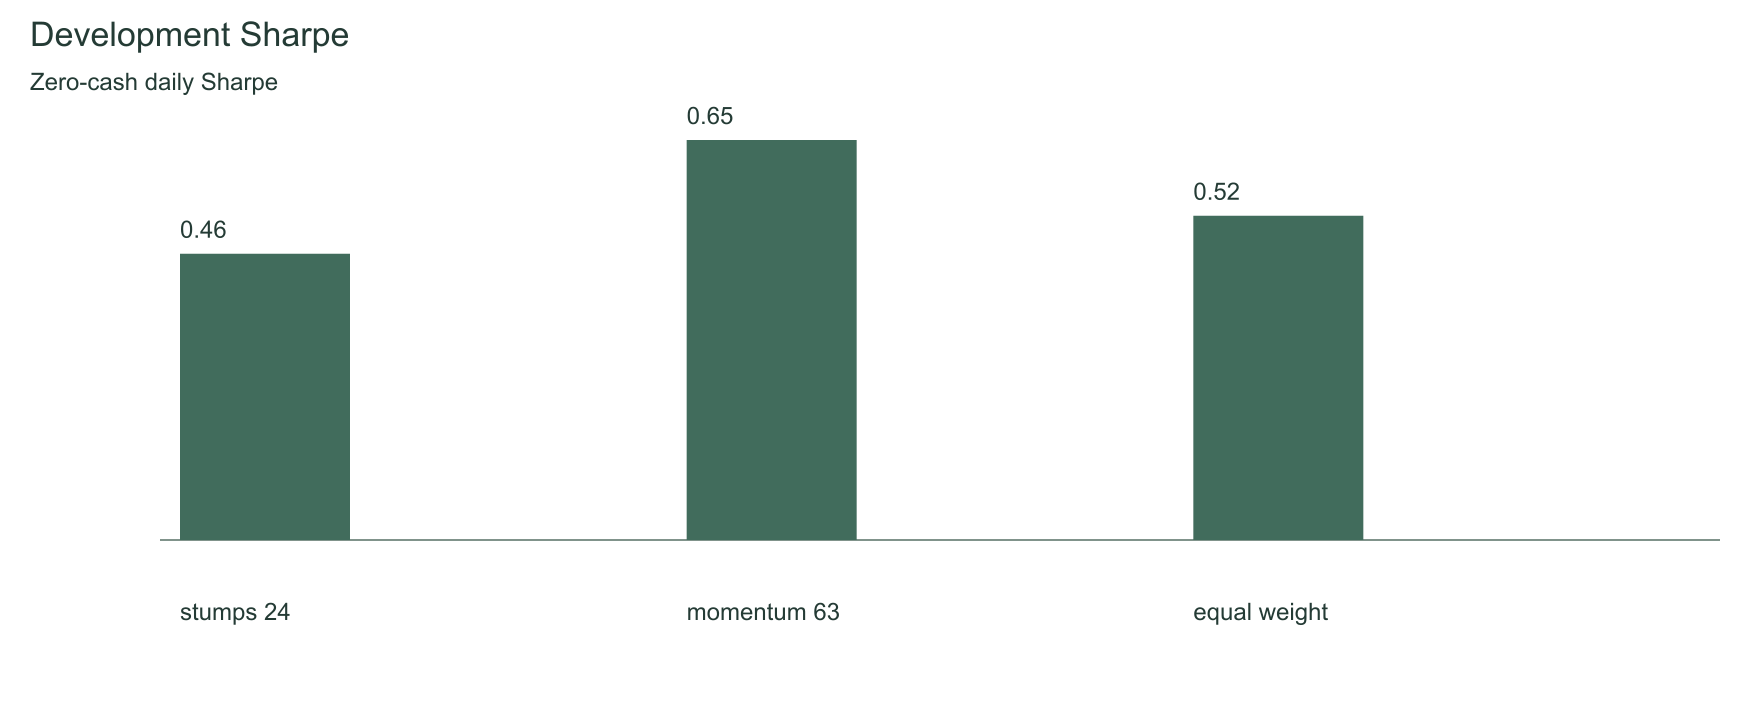

In [3]:
names=[chosen,'momentum_63','equal_weight'];display_bundle(figure(bars('Development Sharpe',[n.replace('_',' ') for n in names],[b['development_metrics'][n]['sharpe_zero_cash'] for n in names],'Zero-cash daily Sharpe')))

## Prediction diagnostics

Post-test rank IC and split counts describe saved fits. They do not change the feature/model specification.

In [4]:
display_bundle(table(['IC statistic','Value'],list(a['rank_ic'].items())));display_bundle(table(['Feature','Saved split count'],list(a['descriptive_stump_split_counts'].items())))

IC statistic,Value
observations,36
mean,-0.02714514778929269
sample_sd,0.4102108733392278
mean_over_sd,-0.06617364276164556
annualisation,Not annualised: overlapping 21-session labels and small date count
positive_fraction,0.4444444444444444


Feature,Saved split count
counts,"{'momentum_21': 0, 'momentum_63': 35, 'volatility_20': 197, 'drawdown_63': 632, 'log_dollar_volume_20': 0}"
interpretation,"Counts are diagnostics of saved fits; not causal importance, not a feature ablation."


## Interpretation

Winning a six-model ML comparison is not proof of beating simple allocation rules. The stored freeze is internally traceable; it is not independently timestamped preregistration or a complete selection-bias correction.